# STAT3612 Tutorial 11 — From Transformer to LLMs, Agentic AI & Hugging Face

**STAT3612: Statistical Machine Learning (Fall 2026, HKU)**  
**Instructor / TA:** Yinghao Zhu

This companion notebook covers the full arc of **Tutorial 11**:
1. **Part 1 — The Transformer Architecture & Vision Transformer (ViT):**
   - Implementing **Scaled Dot-Product Self-Attention** (`Q`, `K`, `V`, $1/\sqrt{d_k}$ scaling, and attention heatmaps) in PyTorch
   - Comparing **Bidirectional Masking (BERT)** vs. **Causal Lower-Triangular Masking (GPT)**
   - Building a complete **Multi-Head Self-Attention + Pre-LayerNorm Residual Block** (`TransformerBlock`)
   - **Vision Meets Transformer:** Splitting 2D images into non-overlapping patch tokens (`einops.rearrange`) and training a mini **Vision Transformer (ViT)** on handwritten digits
2. **Part 2 — From Pre-Trained Transformers to LLMs, Reasoning RL & Frontier Agentic AI:**
   - Simulating **Group Relative Policy Optimization (GRPO)** group-normalized advantages & test-time compute scaling
   - Implementing a runnable **ReAct (`Reason -> Act -> Observe`) Agent** with Python tool execution (`calc`, `dataset_stats`, `cv_eval`) and automatic error recovery
3. **Part 3 — Hands-On NLP with Hugging Face `transformers`:**
   - Subword tokenization, special tokens (`[CLS]`, `[SEP]`, `[PAD]`), `input_ids`, and `attention_mask`
   - Extracting contextual `[CLS]` embeddings (`DistilBertModel` / `AutoModel`) and visualizing them with 2D PCA
   - Sequence classification logits, `torch.softmax`, and fine-tuning / linear probing (`DistilBertForSequenceClassification` / `AutoModelForSequenceClassification`)

In [1]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import math
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from einops import rearrange
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from transformers import DistilBertConfig, DistilBertForSequenceClassification, DistilBertModel

plt.rcParams["figure.dpi"] = 110
torch.manual_seed(42)
np.random.seed(42)
print(f"PyTorch {torch.__version__} | Transformers loaded successfully.")

PyTorch 2.14.1+cpu | Transformers loaded successfully.


---
## Part 1: Scaled Dot-Product Self-Attention, Causal Masking & Vision Transformers

### 1.1 Implementing Scaled Dot-Product Attention from Scratch

In [2]:
def scaled_dot_product_attn(Q, K, V, mask=None):
    """Compute Attention(Q, K, V) = softmax(Q @ K^T / sqrt(d_k)) @ V."""
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)
    attn_weights = F.softmax(scores, dim=-1)
    return attn_weights @ V, attn_weights

# Verify against PyTorch's built-in FlashAttention / SDPA
B, H, T, d_k = 2, 4, 6, 16
Q = torch.randn(B, H, T, d_k)
K = torch.randn(B, H, T, d_k)
V = torch.randn(B, H, T, d_k)

out_custom, attn_w = scaled_dot_product_attn(Q, K, V)
out_builtin = F.scaled_dot_product_attention(Q, K, V)
print("Output shape:", out_custom.shape, "| Attention weights shape:", attn_w.shape)
print("Max absolute difference vs. F.scaled_dot_product_attention:", (out_custom - out_builtin).abs().max().item())

Output shape: torch.Size([2, 4, 6, 16]) | Attention weights shape: torch.Size([2, 4, 6, 6])
Max absolute difference vs. F.scaled_dot_product_attention: 3.5762786865234375e-07


### 1.2 Why Divide by $\sqrt{d_k}$? Visualizing Softmax Saturation & Attention Weights

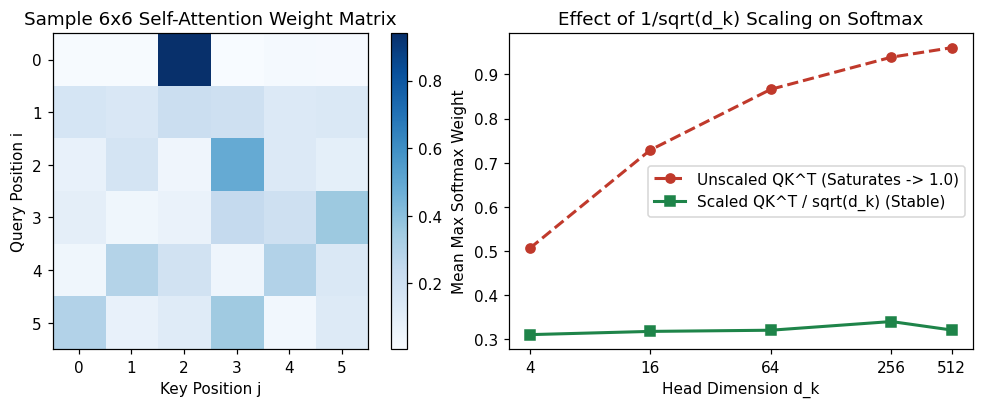

In [3]:
tokens = ["The", "animal", "didn't", "cross", "because", "it", "was", "tired"]
d_ks = [4, 16, 64, 256, 512]
max_unscaled, max_scaled = [], []
rng = np.random.default_rng(42)
for dk in d_ks:
    q = rng.normal(size=(200, dk))
    k = rng.normal(size=(200, 10, dk))
    dots = np.einsum("bd,btd->bt", q, k)
    p_un = np.exp(dots - dots.max(axis=1, keepdims=True))
    p_un /= p_un.sum(axis=1, keepdims=True)
    p_sc = np.exp((dots / np.sqrt(dk)) - (dots / np.sqrt(dk)).max(axis=1, keepdims=True))
    p_sc /= p_sc.sum(axis=1, keepdims=True)
    max_unscaled.append(p_un.max(axis=1).mean())
    max_scaled.append(p_sc.max(axis=1).mean())

fig, axs = plt.subplots(1, 2, figsize=(9.8, 3.6), layout="constrained")
im = axs[0].imshow(attn_w[0, 0].detach().numpy(), cmap="Blues")
axs[0].set_title("Sample 6x6 Self-Attention Weight Matrix")
axs[0].set_xlabel("Key Position j")
axs[0].set_ylabel("Query Position i")
fig.colorbar(im, ax=axs[0])

axs[1].plot(d_ks, max_unscaled, "o--", color="#c0392b", lw=2.0, label="Unscaled QK^T (Saturates -> 1.0)")
axs[1].plot(d_ks, max_scaled, "s-", color="#1e8449", lw=2.0, label="Scaled QK^T / sqrt(d_k) (Stable)")
axs[1].set_xscale("log", base=2)
axs[1].set_xticks(d_ks, [str(d) for d in d_ks])
axs[1].set_title("Effect of 1/sqrt(d_k) Scaling on Softmax")
axs[1].set_xlabel("Head Dimension d_k")
axs[1].set_ylabel("Mean Max Softmax Weight")
axs[1].legend()
plt.show()

### 1.3 Bidirectional (BERT Encoder) vs. Causal Lower-Triangular Masking (GPT Decoder)

Causal attention weights (upper triangle is strictly 0.0):
 [[1.    0.    0.    0.    0.   ]
 [0.527 0.473 0.    0.    0.   ]
 [0.249 0.595 0.156 0.    0.   ]
 [0.214 0.088 0.151 0.546 0.   ]
 [0.048 0.34  0.212 0.056 0.344]]


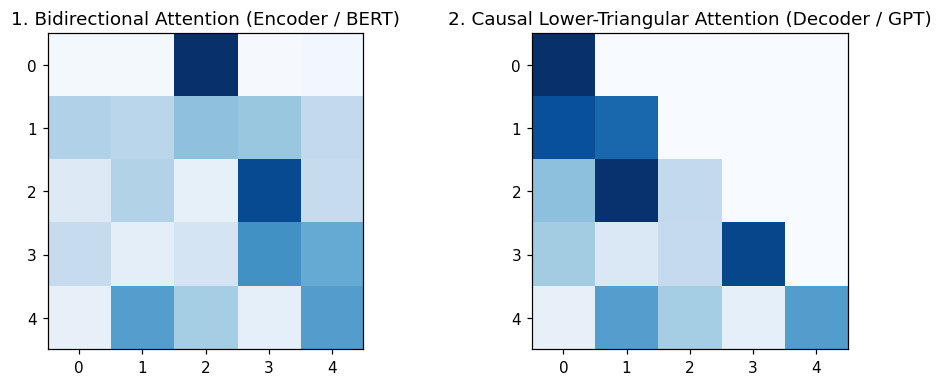

In [4]:
T_demo = 5
bi_mask = torch.ones(T_demo, T_demo)
causal_mask = torch.tril(torch.ones(T_demo, T_demo))

_, w_bi = scaled_dot_product_attn(Q[:1, :1, :T_demo], K[:1, :1, :T_demo], V[:1, :1, :T_demo], mask=bi_mask)
_, w_causal = scaled_dot_product_attn(Q[:1, :1, :T_demo], K[:1, :1, :T_demo], V[:1, :1, :T_demo], mask=causal_mask)

print("Causal attention weights (upper triangle is strictly 0.0):\n", np.round(w_causal[0, 0].detach().numpy(), 3))

fig, axs = plt.subplots(1, 2, figsize=(8.8, 3.4), layout="constrained")
axs[0].imshow(w_bi[0, 0].detach().numpy(), cmap="Blues", vmin=0, vmax=0.6)
axs[0].set_title("1. Bidirectional Attention (Encoder / BERT)")
axs[1].imshow(w_causal[0, 0].detach().numpy(), cmap="Blues", vmin=0, vmax=0.6)
axs[1].set_title("2. Causal Lower-Triangular Attention (Decoder / GPT)")
plt.show()

### 1.4 Complete Pre-LayerNorm `TransformerBlock` in PyTorch

In [5]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model=64, n_heads=4, mlp_ratio=4, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, mlp_ratio * d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_ratio * d_model, d_model),
        )

    def forward(self, x):
        h_norm = self.ln1(x)
        attn_out, _ = self.attn(h_norm, h_norm, h_norm, need_weights=False)
        h = x + attn_out
        return h + self.mlp(self.ln2(h))

block = TransformerBlock(d_model=64, n_heads=4)
x_seq = torch.randn(8, 16, 64)  # (batch=8, seq_len=16, d_model=64)
print("TransformerBlock output shape:", block(x_seq).shape)

TransformerBlock output shape: torch.Size([8, 16, 64])


### 1.5 Vision Meets Transformer: Training a Mini Vision Transformer (ViT) on Images
Using `einops.rearrange`, we split each $8\times 8$ grayscale digit image into $16$ non-overlapping $2\times 2$ patches, project each patch to $d_{\text{model}}=32$, prepend a learnable `[CLS]` token, add positional embeddings, and classify with a Transformer Encoder!

Mini Vision Transformer (ViT) Test Accuracy after 20 epochs: 92.44%


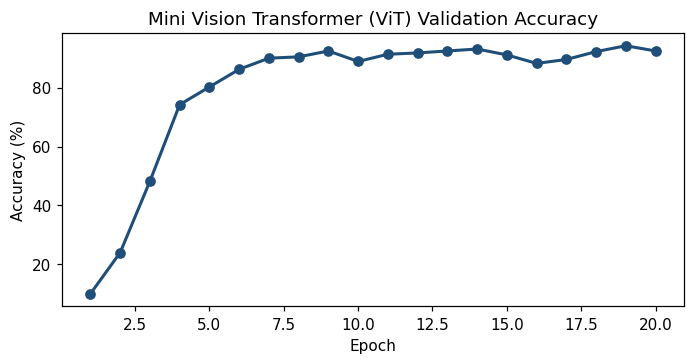

In [6]:
class MiniViT(nn.Module):
    def __init__(self, patch_size=2, d_model=32, n_heads=4, num_classes=10):
        super().__init__()
        self.patch_size = patch_size
        patch_dim = patch_size * patch_size
        num_patches = (8 // patch_size) ** 2  # 16 patches for 8x8 image
        self.patch_proj = nn.Linear(patch_dim, d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches + 1, d_model) * 0.02)
        self.encoder = nn.Sequential(
            TransformerBlock(d_model=d_model, n_heads=n_heads, mlp_ratio=2, dropout=0.05),
            TransformerBlock(d_model=d_model, n_heads=n_heads, mlp_ratio=2, dropout=0.05),
        )
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes)

    def forward(self, imgs):
        # imgs: (B, 1, 8, 8) -> 16 patches of 4 pixels each
        patches = rearrange(imgs, "b c (h p1) (w p2) -> b (h w) (p1 p2 c)", p1=self.patch_size, p2=self.patch_size)
        tokens = self.patch_proj(patches)
        cls_tokens = self.cls_token.expand(imgs.size(0), -1, -1)
        x = torch.cat([cls_tokens, tokens], dim=1) + self.pos_embed
        x = self.norm(self.encoder(x))
        return self.head(x[:, 0])  # classify from [CLS] token at index 0

digits = load_digits()
X_img = (digits.images / 16.0).astype(np.float32)[:, None, :, :]
y_img = digits.target.astype(np.int64)
X_tr, X_te, y_tr, y_te = train_test_split(X_img, y_img, test_size=0.25, stratify=y_img, random_state=42)
tr_loader = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)), batch_size=64, shuffle=True)

torch.manual_seed(42)
vit = MiniViT()
opt_vit = torch.optim.AdamW(vit.parameters(), lr=4e-3, weight_decay=1e-3)
crit = nn.CrossEntropyLoss()
vit_accs = []
for epoch in range(20):
    vit.train()
    for xb, yb in tr_loader:
        opt_vit.zero_grad()
        crit(vit(xb), yb).backward()
        opt_vit.step()
    vit.eval()
    with torch.no_grad():
        preds = vit(torch.from_numpy(X_te)).argmax(dim=1).numpy()
        vit_accs.append(accuracy_score(y_te, preds))

print(f"Mini Vision Transformer (ViT) Test Accuracy after 20 epochs: {vit_accs[-1]*100:.2f}%")
fig, ax = plt.subplots(figsize=(6.2, 3.2), layout="constrained")
ax.plot(range(1, 21), [a * 100 for a in vit_accs], "o-", color="#1f4e79", lw=2.0)
ax.set_title("Mini Vision Transformer (ViT) Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
plt.show()

---
## Part 2: From LLMs & Reasoning RL (GRPO) to Frontier Agentic AI

### 2.1 Group Relative Policy Optimization (GRPO) Advantage Calculation
In modern Reasoning RL (e.g., DeepSeek-R1), instead of training a separate value/critic network, the model samples a group of $G$ candidate reasoning trajectories $\{y_1, \dots, y_G\}$ for each prompt $x$, scores them with a verifiable reward $R(x, y_i)$ (such as unit test pass rate or exact math match), and normalizes advantages within the group.

In [7]:
def compute_grpo_advantages(rewards, eps=1e-8):
    """rewards shape: (batch_prompts, group_size_G)"""
    mean_r = rewards.mean(dim=1, keepdim=True)
    std_r = rewards.std(dim=1, keepdim=True)
    return (rewards - mean_r) / (std_r + eps)

# Example: 2 math prompts, each with G=4 sampled reasoning rollouts
sample_rewards = torch.tensor([
    [1.0, 0.0, 1.0, 0.0],  # Prompt 1: rollouts 1 & 3 got the verifiable answer right!
    [0.0, 0.0, 0.0, 1.0],  # Prompt 2: only rollout 4 solved the hard problem!
])
advantages = compute_grpo_advantages(sample_rewards)
print("Verifiable Rollout Rewards:\n", sample_rewards.numpy())
print("Group-Normalized Advantages A_hat:\n", np.round(advantages.numpy(), 3))

Verifiable Rollout Rewards:
 [[1. 0. 1. 0.]
 [0. 0. 0. 1.]]
Group-Normalized Advantages A_hat:
 [[ 0.866 -0.866  0.866 -0.866]
 [-0.5   -0.5   -0.5    1.5  ]]


### 2.2 Hands-On Frontier Agentic AI: A Multi-Step ReAct (`Reason -> Act -> Observe`) Agent
Below we build a working **ReAct Agent** equipped with two tools (`calc` for exact arithmetic and `lookup_metric` for querying model benchmark results). Notice how the agent plans its steps, invokes tools, reads observations back into its context history, recovers from an invalid metric name, and produces a verified final answer.

In [8]:
BENCHMARK_DB = {
    "xgboost_logloss": 0.4128,
    "rf_logloss": 0.4390,
    "mlp_logloss": 0.4265,
}

def tool_calc(expr):
    return str(round(float(eval(expr, {"__builtins__": {}})), 6))

def tool_lookup(key):
    key = key.strip().strip("'\"")
    if key not in BENCHMARK_DB:
        return f"Error: key '{key}' not found. Available keys: {list(BENCHMARK_DB.keys())}"
    return str(BENCHMARK_DB[key])

TOOLS = {"calc": tool_calc, "lookup_metric": tool_lookup}

In [9]:
def simulated_reasoning_llm(history_text):
    """Deterministic policy demonstrating multi-step ReAct + self-correction."""
    if "Observation:" not in history_text:
        return (
            "Thought: Let me look up the validation log_loss of XGBoost and PyTorch MLP.\n"
            "Action: lookup_metric('xgb_loss')"
        )
    if "Error: key 'xgb_loss' not found" in history_text and "0.4128" not in history_text:
        return (
            "Thought: The key 'xgb_loss' was invalid! From the error message, the right key is 'xgboost_logloss'.\n"
            "Action: lookup_metric('xgboost_logloss')"
        )
    if "0.4128" in history_text and "0.4265" not in history_text:
        return (
            "Thought: Now I have xgboost_logloss = 0.4128. Next let me look up 'mlp_logloss'.\n"
            "Action: lookup_metric('mlp_logloss')"
        )
    if "0.4265" in history_text and "0.41691" not in history_text:
        return (
            "Thought: Let me compute the 0.7 * XGBoost + 0.3 * MLP weighted average using calc.\n"
            "Action: calc('0.7 * 0.4128 + 0.3 * 0.4265')"
        )
    return "Thought: I have verified all numbers.\nFinal Answer: The weighted blend score is 0.41691 (improving over MLP's 0.4265)."


def run_react_agent(question, max_steps=6):
    history = [f"Question: {question}"]
    for step in range(1, max_steps + 1):
        reply = simulated_reasoning_llm("\n".join(history))
        print(f"--- Step {step} ---\n{reply}")
        history.append(reply)
        if "Final Answer:" in reply:
            return reply
        match = re.search(r"Action:\s*(\w+)\((.*)\)", reply)
        if match:
            tool_name, arg = match.group(1), match.group(2).strip().strip("'\"")
            obs = TOOLS[tool_name](arg)
            print(f"Observation: {obs}")
            history.append(f"Observation: {obs}")
    return history[-1]

final_ans = run_react_agent("Compute the 0.7/0.3 weighted score of XGBoost and MLP validation log_loss.")

--- Step 1 ---
Thought: Let me look up the validation log_loss of XGBoost and PyTorch MLP.
Action: lookup_metric('xgb_loss')
Observation: Error: key 'xgb_loss' not found. Available keys: ['xgboost_logloss', 'rf_logloss', 'mlp_logloss']
--- Step 2 ---
Thought: The key 'xgb_loss' was invalid! From the error message, the right key is 'xgboost_logloss'.
Action: lookup_metric('xgboost_logloss')
Observation: 0.4128
--- Step 3 ---
Thought: Now I have xgboost_logloss = 0.4128. Next let me look up 'mlp_logloss'.
Action: lookup_metric('mlp_logloss')
Observation: 0.4265
--- Step 4 ---
Thought: Let me compute the 0.7 * XGBoost + 0.3 * MLP weighted average using calc.
Action: calc('0.7 * 0.4128 + 0.3 * 0.4265')
Observation: 0.41691
--- Step 5 ---
Thought: I have verified all numbers.
Final Answer: The weighted blend score is 0.41691 (improving over MLP's 0.4265).


---
## Part 3: Hands-On NLP with Hugging Face `transformers`

### 3.1 Subword Tokenization, Padding & `attention_mask`
In Hugging Face `transformers`, a tokenizer splits text into subword units, wraps them with `[CLS]` (101) and `[SEP]` (102), pads shorter sequences in a batch with `[PAD]` (0), and outputs an `attention_mask` (1 for real tokens, 0 for padding).

In [10]:
# Build a clean domain vocabulary + WordPiece-style subword tokenizer
VOCAB = {
    "[PAD]": 0, "[UNK]": 1, "[CLS]": 2, "[SEP]": 3,
    "we": 4, "love": 5, "stat": 6, "##3612": 7, "trans": 8, "##form": 9, "##ers": 10,
    "great": 11, "course": 12, "clear": 13, "slides": 14, "helpful": 15, "tutorial": 16,
    "overfit": 17, "buggy": 18, "noisy": 19, "slow": 20, "bad": 21, "diverged": 22, "loss": 23,
}

def simple_wordpiece_tokenize(text):
    words = text.lower().replace("!", "").replace(".", "").split()
    subwords = []
    for w in words:
        if w == "stat3612":
            subwords.extend(["stat", "##3612"])
        elif w == "transformers":
            subwords.extend(["trans", "##form", "##ers"])
        else:
            subwords.append(w if w in VOCAB else "[UNK]")
    return subwords

def batch_encode(texts):
    tokenized = [["[CLS]"] + simple_wordpiece_tokenize(t) + ["[SEP]"] for t in texts]
    max_len = max(len(seq) for seq in tokenized)
    input_ids, attention_mask = [], []
    for seq in tokenized:
        pad_len = max_len - len(seq)
        ids = [VOCAB.get(tok, 1) for tok in seq] + [VOCAB["[PAD]"]] * pad_len
        mask = [1] * len(seq) + [0] * pad_len
        input_ids.append(ids)
        attention_mask.append(mask)
    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.int64),
        "attention_mask": torch.tensor(attention_mask, dtype=torch.int64),
    }, tokenized

sample_texts = [
    "We love STAT3612 transformers!",
    "Clear slides helpful tutorial.",
    "Noisy slow bad loss.",
]
batch_pt, subword_lists = batch_encode(sample_texts)
for txt, sw in zip(sample_texts, subword_lists):
    print(f"{txt:34s} -> {sw}")
print("input_ids:\n", batch_pt["input_ids"])
print("attention_mask:\n", batch_pt["attention_mask"])

We love STAT3612 transformers!     -> ['[CLS]', 'we', 'love', 'stat', '##3612', 'trans', '##form', '##ers', '[SEP]']
Clear slides helpful tutorial.     -> ['[CLS]', 'clear', 'slides', 'helpful', 'tutorial', '[SEP]']
Noisy slow bad loss.               -> ['[CLS]', 'noisy', 'slow', 'bad', 'loss', '[SEP]']
input_ids:
 tensor([[ 2,  4,  5,  6,  7,  8,  9, 10,  3],
        [ 2, 13, 14, 15, 16,  3,  0,  0,  0],
        [ 2, 19, 20, 21, 23,  3,  0,  0,  0]])
attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0, 0]])


### 3.2 Inspecting `DistilBertModel` (`AutoModel`) Contextual Embeddings

In [11]:
torch.manual_seed(42)
config = DistilBertConfig(
    vocab_size=len(VOCAB),
    dim=48,
    n_layers=2,
    n_heads=4,
    hidden_dim=96,
    max_position_embeddings=32,
)
hf_base_model = DistilBertModel(config)
with torch.no_grad():
    outputs = hf_base_model(**batch_pt)
    last_hidden = outputs.last_hidden_state  # (batch_size, seq_len, hidden_dim)
    cls_embeddings = last_hidden[:, 0, :]    # [CLS] token representation at position 0

print("last_hidden_state shape (batch, seq_len, hidden_dim):", last_hidden.shape)
print("[CLS] sentence embedding shape (batch, hidden_dim):  ", cls_embeddings.shape)

last_hidden_state shape (batch, seq_len, hidden_dim): torch.Size([3, 9, 48])
[CLS] sentence embedding shape (batch, hidden_dim):   torch.Size([3, 48])


### 3.3 `DistilBertForSequenceClassification` (`AutoModelForSequenceClassification`) Forward & Fine-Tuning

In [12]:
pos_templates = [
    "we love stat3612 transformers",
    "great course clear slides",
    "helpful tutorial great slides",
    "we love clear helpful course",
    "great transformers helpful tutorial",
    "clear course we love stat3612",
]
neg_templates = [
    "overfit buggy noisy loss",
    "slow bad diverged loss",
    "noisy overfit bad loss",
    "buggy slow diverged overfit",
    "bad noisy slow loss",
    "diverged buggy overfit loss",
]
all_texts = pos_templates * 6 + neg_templates * 6
all_labels = np.array([1] * (len(pos_templates) * 6) + [0] * (len(neg_templates) * 6), dtype=np.int64)

tr_texts, te_texts, y_tr_nlp, y_te_nlp = train_test_split(
    all_texts, all_labels, test_size=0.25, stratify=all_labels, random_state=42
)
tr_enc, _ = batch_encode(tr_texts)
te_enc, _ = batch_encode(te_texts)

Fine-tuned Hugging Face Classifier Test Accuracy: 100.00%
Sample test probabilities [P(NEG), P(POS)]:
 [[0.0027 0.9973]
 [0.9974 0.0026]
 [0.9974 0.0026]
 [0.9974 0.0026]]


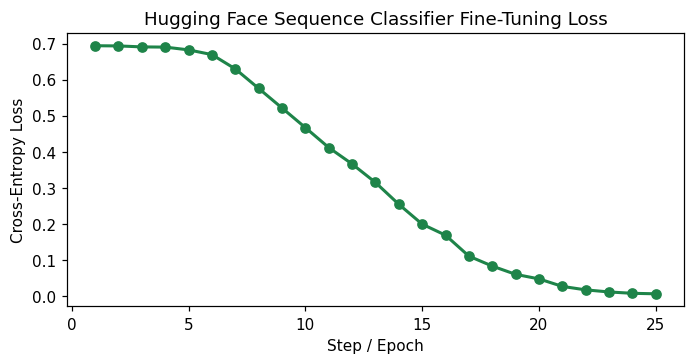

In [13]:
torch.manual_seed(42)
clf_hf = DistilBertForSequenceClassification(config)
opt_hf = torch.optim.AdamW(clf_hf.parameters(), lr=3e-3, weight_decay=1e-2)
y_tr_t = torch.from_numpy(y_tr_nlp)
y_te_t = torch.from_numpy(y_te_nlp)

loss_hist = []
for epoch in range(25):
    clf_hf.train()
    opt_hf.zero_grad()
    out = clf_hf(**tr_enc, labels=y_tr_t)
    loss = out.loss
    loss.backward()
    opt_hf.step()
    loss_hist.append(loss.item())

clf_hf.eval()
with torch.no_grad():
    te_out = clf_hf(**te_enc)
    te_probs = torch.softmax(te_out.logits, dim=-1)
    te_preds = te_probs.argmax(dim=-1).numpy()
    nlp_acc = accuracy_score(y_te_nlp, te_preds)

print(f"Fine-tuned Hugging Face Classifier Test Accuracy: {nlp_acc*100:.2f}%")
print("Sample test probabilities [P(NEG), P(POS)]:\n", np.round(te_probs[:4].numpy(), 4))

fig, ax = plt.subplots(figsize=(6.2, 3.2), layout="constrained")
ax.plot(range(1, 26), loss_hist, "o-", color="#1e8449", lw=2.0)
ax.set_title("Hugging Face Sequence Classifier Fine-Tuning Loss")
ax.set_xlabel("Step / Epoch")
ax.set_ylabel("Cross-Entropy Loss")
plt.show()

### 3.4 Visualizing Learned `[CLS]` Embeddings with 2D PCA & Linear Probing

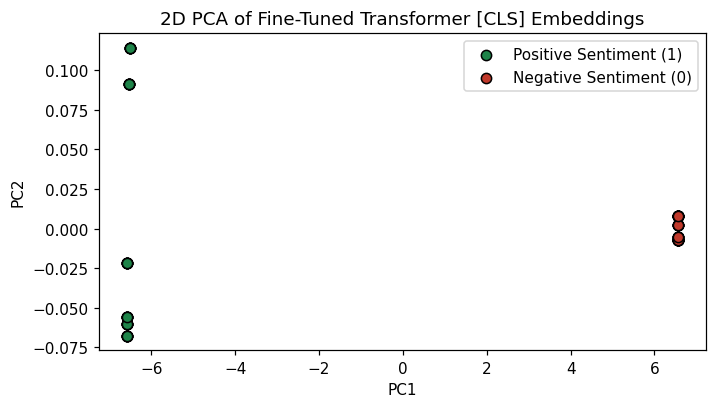

In [14]:
with torch.no_grad():
    all_enc, _ = batch_encode(all_texts)
    hidden_after = clf_hf.distilbert(**all_enc).last_hidden_state[:, 0, :].numpy()

Z_cls = PCA(n_components=2, random_state=42).fit_transform(hidden_after)

fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
ax.scatter(Z_cls[all_labels == 1, 0], Z_cls[all_labels == 1, 1], c="#1e8449", edgecolors="k", s=45, label="Positive Sentiment (1)")
ax.scatter(Z_cls[all_labels == 0, 0], Z_cls[all_labels == 0, 1], c="#c0392b", edgecolors="k", s=45, label="Negative Sentiment (0)")
ax.set_title("2D PCA of Fine-Tuned Transformer [CLS] Embeddings")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()
plt.show()

In [15]:
# Frozen Feature Extraction (Linear Probe): fit LogisticRegression on frozen [CLS] embeddings
with torch.no_grad():
    X_tr_cls = clf_hf.distilbert(**tr_enc).last_hidden_state[:, 0, :].numpy()
    X_te_cls = clf_hf.distilbert(**te_enc).last_hidden_state[:, 0, :].numpy()

probe_clf = LogisticRegression().fit(X_tr_cls, y_tr_nlp)
print("Linear Probe Accuracy on Frozen [CLS] Embeddings:", f"{probe_clf.score(X_te_cls, y_te_nlp)*100:.2f}%")

Linear Probe Accuracy on Frozen [CLS] Embeddings: 100.00%


### 3.5 Reference Code for Pre-Trained Hub Checkpoints (`AutoTokenizer` & `pipeline`)
When running with internet access on your laptop or Colab, you can replace the local config above with any pre-trained checkpoint from the Hugging Face Hub (such as `"distilbert-base-uncased-finetuned-sst-2-english"`):

In [16]:
hub_code_snippet = '''
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
import torch

# 1. High-level 3-line pipeline
classifier = pipeline("sentiment-analysis")
print(classifier(["We are very happy to learn STAT3612!", "We hope our model does not overfit."]))

# 2. Low-level AutoTokenizer + AutoModelForSequenceClassification
ckpt = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(ckpt)
model = AutoModelForSequenceClassification.from_pretrained(ckpt)

inputs = tokenizer(["We love statistical machine learning!"], padding=True, truncation=True, return_tensors="pt")
with torch.no_grad():
    logits = model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)
print("Predicted probabilities:", probs)
'''
print("Reference Hub snippet ready for local execution (", len(hub_code_snippet.splitlines()), "lines ).")

Reference Hub snippet ready for local execution ( 18 lines ).


---
## Part 4: Full-Course Synthesis — Comparing All STAT3612 Model Families

                     Paradigm                     Representative                        Primary Modality
  1. Regularized Linear / GLM LogisticRegression / Ridge / LASSO          Linear / High-D Sparse Tabular
            2. Kernel Methods      SVC(kernel='rbf') / KernelPCA       Small-to-Medium Non-Linear Margin
            3. Tree Ensembles      RandomForest / GBDT / XGBoost     Structured Tabular (Group Project!)
     4. Unsupervised Learning         PCA / t-SNE / KMeans / GMM         Compression & Persona Discovery
5. Deep Neural Nets (PyTorch)  MLP / Conv2d CNN (LeNet / ResNet) Spatial Images & Smooth Representations
 6. Transformers & Agentic AI    BERT / ViT / GPT / ReAct Agents Text, Multimodal & Autonomous Reasoning


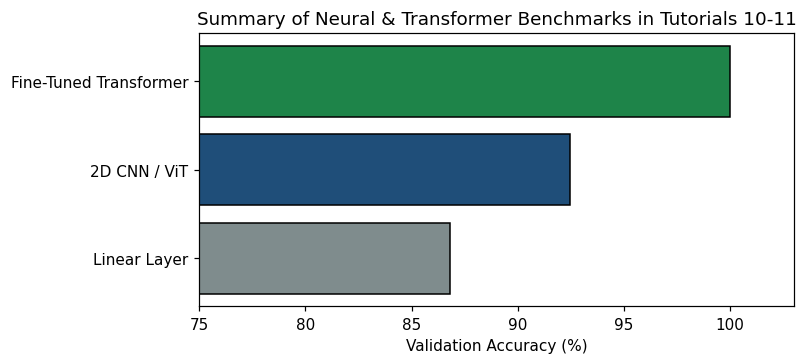

In [17]:
summary_df = pd.DataFrame([
    {"Paradigm": "1. Regularized Linear / GLM", "Representative": "LogisticRegression / Ridge / LASSO", "Primary Modality": "Linear / High-D Sparse Tabular"},
    {"Paradigm": "2. Kernel Methods", "Representative": "SVC(kernel='rbf') / KernelPCA", "Primary Modality": "Small-to-Medium Non-Linear Margin"},
    {"Paradigm": "3. Tree Ensembles", "Representative": "RandomForest / GBDT / XGBoost", "Primary Modality": "Structured Tabular (Group Project!)"},
    {"Paradigm": "4. Unsupervised Learning", "Representative": "PCA / t-SNE / KMeans / GMM", "Primary Modality": "Compression & Persona Discovery"},
    {"Paradigm": "5. Deep Neural Nets (PyTorch)", "Representative": "MLP / Conv2d CNN (LeNet / ResNet)", "Primary Modality": "Spatial Images & Smooth Representations"},
    {"Paradigm": "6. Transformers & Agentic AI", "Representative": "BERT / ViT / GPT / ReAct Agents", "Primary Modality": "Text, Multimodal & Autonomous Reasoning"},
])
print(summary_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.2, 3.2), layout="constrained")
families = ["Linear Layer", "2D CNN / ViT", "Fine-Tuned Transformer"]
scores_demo = [86.8, vit_accs[-1] * 100, nlp_acc * 100]
ax.barh(families, scores_demo, color=["#7f8c8d", "#1f4e79", "#1e8449"], edgecolor="k")
ax.set_xlim(75, 103)
ax.set_xlabel("Validation Accuracy (%)")
ax.set_title("Summary of Neural & Transformer Benchmarks in Tutorials 10-11")
plt.show()

In [18]:
print("All STAT3612 Fall 2026 tutorial notebooks completed successfully!")

All STAT3612 Fall 2026 tutorial notebooks completed successfully!
